# COMP8240 Final Project — Constructed data: Controlled Question Quality Dataset
**Nabin Basnet (48441147)**

Starts from questions that all three QGEval annotators rated 3/3 on all seven dimensions, breaks exactly **one** dimension per item (5 base questions × 7 dimensions = 35 items), and tests whether reference-based metrics detect each planted error.

The completed dataset is `data/controlled/controlled_question_quality_dataset.csv` (rebuild it with `python src/build_controlled_dataset.py`). The saved outputs below are from the run reported in the paper.

## Step 1 — Setup

In [ ]:
!pip install -q pandas openpyxl nltk rouge-score bert-score matplotlib
!git clone -q https://github.com/WeipingFu/QGEval.git
import sys, platform, random
import pandas as pd
print("Python:", sys.version.split()[0], "|", platform.platform())

Python: 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39


## Step 2 — Collection: pick 5 human-verified valid questions


In [ ]:
SEED = 42
N_SQUAD, N_HOTPOT = 3, 2          # 5 source passages in total
MAX_PASSAGE_WORDS = 120
DIMS = ["fluency", "clarity", "conciseness", "relevance",
        "consistency", "answerability", "answer_consistency"]

h = pd.read_excel("QGEval/data/scores.xlsx")
gen = h[~h.source.str.contains("reference")].copy()
gen["dataset"] = gen.source.str.split("_").str[0]
gen["model"] = gen.source.str.split("_", n=1).str[1]
gen["passage_words"] = gen.passage.str.split().str.len()
# a candidate valid question: rated 3/3 on ALL seven dimensions by ALL three QGEval annotators
perfect = gen[(gen[DIMS] == 3).all(axis=1)
              & (gen.prediction.str.strip().str.lower() != gen.reference.str.strip().str.lower())
              & (gen.passage_words <= MAX_PASSAGE_WORDS)
              & gen.apply(lambda r: str(r.answer) in r.passage, axis=1)]
print(f"Generated questions in QGEval: {len(gen):,}")
print(f"Rated perfect (3 on all 7 dims by all 3 annotators): {(gen[DIMS] == 3).all(axis=1).sum():,}")
print(f"Candidates after filters (differs from reference, passage <= {MAX_PASSAGE_WORDS} words, answer in passage): "
      f"{len(perfect):,} questions from {perfect.id.nunique()} passages")

rng = random.Random(SEED)
picked = []
for ds, n in [("SQuAD", N_SQUAD), ("HotpotQA", N_HOTPOT)]:
    ids = sorted(perfect[perfect.dataset == ds].id.unique())
    for pid in rng.sample(ids, n):
        options = perfect[perfect.id == pid].sort_values("source")
        picked.append(options.iloc[rng.randrange(len(options))])
src = pd.DataFrame(picked).reset_index(drop=True)
src.insert(0, "base_id", [f"B{i+1}" for i in range(len(src))])
pd.set_option("display.max_colwidth", 90)
print("\nSelected base items (valid question = human-verified perfect QGEval question):\n")
for _, r in src.iterrows():
    print(f"{r.base_id} [{r.dataset}, {r.model}]  answer: {r.answer}")
    print(f"    valid question    : {r.prediction}")
    print(f"    reference question: {r.reference}")
    print(f"    passage ({r.passage_words} words): {r.passage[:200]}...\n")

Generated questions in QGEval: 2,800
Rated perfect (3 on all 7 dims by all 3 annotators): 1,369
Candidates after filters (differs from reference, passage <= 120 words, answer in passage): 581 questions from 83 passages

Selected base items (valid question = human-verified perfect QGEval question):

B1 [SQuAD, T5-large_finetune]  answer: 40
    valid question    : How many men did Dinwiddie send to Fort Duquesne?
    reference question: How many men did Duquesne send to relieve Saint-Pierre?
    passage (94 words): Even before Washington returned, Dinwiddie had sent a company of 40 men under William Trent to that point, where in the early months of 1754 they began construction of a small stockaded fort. Governor...

B2 [SQuAD, FlanT5-xl_lora]  answer: increasing unemployment
    valid question    : What happens when less workers are required in proportion to capital inputs?
    reference question: When less workers are required, what happens to the job market?
    passage (97 words): In

## Step 3 — Build the item template
35 rows: each of the 5 valid questions × 7 target dimensions, with the perturbation rule for each dimension.

In [ ]:
RULES = {
    "fluency":            "Break the grammar or word order so it reads badly (keep the meaning recoverable).",
    "clarity":            "Make it vague or ambiguous, e.g. replace key names with 'it', 'they', 'that thing'.",
    "conciseness":        "Add redundant or repeated words without changing the meaning.",
    "relevance":          "Ask about something unimportant or unrelated to the passage's main content.",
    "consistency":        "Change a fact so the question contradicts the passage (wrong date, name, number).",
    "answerability":      "Ask for information the passage does not contain.",
    "answer_consistency": "Keep it answerable from the passage, but so that the given answer is NOT its answer.",
}
EXAMPLE = {   # passage: "Canberra became the capital of Australia in 1913."  answer: Canberra
    "fluency":            "Which city capital became of Australia 1913 in the?",
    "clarity":            "Which one became it there in that year?",
    "conciseness":        "Which particular city, out of all the cities, was the one that became the capital city of Australia in 1913?",
    "relevance":          "Which city has the best coffee in Australia?",
    "consistency":        "Which city became the capital of Australia in 1950?",
    "answerability":      "Which city was chosen as Australia's capital after a public vote?",
    "answer_consistency": "In what year did Canberra become the capital of Australia?",
}
rows = []
for _, r in src.iterrows():
    for d in DIMS:
        rows.append({"item_id": f"{r.base_id}-{d[:4].upper() if d != 'answer_consistency' else 'ANSC'}",
                     "base_id": r.base_id, "dataset": r.dataset, "passage": r.passage,
                     "answer": r.answer, "reference_question": r.reference,
                     "valid_question": r.prediction, "target_dimension": d,
                     "how_to_perturb": RULES[d], "perturbed_question": "",
                     "perturbation_type": "", "only_target_broken": "", "notes": ""})
build = pd.DataFrame(rows)
guide = pd.DataFrame({"dimension": DIMS, "rule": [RULES[d] for d in DIMS],
                      "example (passage: 'Canberra became the capital of Australia in 1913.', answer: Canberra, "
                      "valid: 'Which city became the capital of Australia in 1913?')": [EXAMPLE[d] for d in DIMS]})
howto = pd.DataFrame({"column": ["perturbed_question", "perturbation_type", "only_target_broken", "notes"],
                      "what to write": [
                          "Modified version of valid_question that breaks ONLY the target dimension",
                          "A few words naming what was changed, e.g. 'word order scrambled', 'date changed'",
                          "yes / partly / no: does the edit break only the target dimension?",
                          "Optional: anything difficult, e.g. 'fluency error also hurts clarity'"]})
with pd.ExcelWriter("controlled_dataset_build.xlsx") as xw:
    build.to_excel(xw, sheet_name="build", index=False)
    guide.to_excel(xw, sheet_name="perturbation_guide", index=False)
    howto.to_excel(xw, sheet_name="how_to_fill", index=False)
src.to_csv("controlled_base_items.csv", index=False)
print(f"Template: {len(build)} items = {len(src)} base questions x {len(DIMS)} target dimensions")
from google.colab import files
files.download("controlled_dataset_build.xlsx")

## How the perturbed questions were written and labelled
- **Perturbed question:** one per row, following the fixed rule for its target dimension (`perturbation_rule`). Drafts were produced with a large language model under these rules; the author reviewed every item and no question text needed rewriting.
- **only_target_broken:** the author's label (`yes` = only the target dimension is broken; `partly` = another dimension is also affected; `no` = target not broken).
- **Blind re-check (Step 7):** the perturbed questions were shuffled with the target hidden and the author named the main error of each.

The completed file is `data/controlled/controlled_question_quality_dataset.csv`.

## Step 4 — Validate the completed dataset

In [ ]:
# Load the completed dataset file (controlled_dataset_build.xlsx) and run quality checks.
import os, re
from google.colab import files
for name in files.upload():
    clean = re.sub(r" \(\d+\)", "", name)
    if clean != name:
        os.replace(name, clean)

ds = pd.read_excel("controlled_dataset_build.xlsx", sheet_name="build")
ds["perturbed_question"] = ds.perturbed_question.fillna("").astype(str).str.strip()
ds["only_target_broken"] = ds.only_target_broken.fillna("").astype(str).str.strip().str.lower()
checks = {
    "items": len(ds),
    "perturbed question written": int((ds.perturbed_question != "").sum()),
    "identical to valid question (must fix)": int((ds.perturbed_question.str.lower() == ds.valid_question.str.lower()).sum()),
    "duplicate perturbed questions": int(ds[ds.perturbed_question != ""].perturbed_question.duplicated().sum()),
    "perturbation_type filled": int(ds.perturbation_type.notna().sum()),
    "only_target_broken filled (yes/partly/no)": int(ds.only_target_broken.isin(["yes", "partly", "no"]).sum()),
}
for k, v in checks.items():
    print(f"{k:45s}: {v}")
done = ds[(ds.perturbed_question != "") & (ds.perturbed_question.str.lower() != ds.valid_question.str.lower())].copy()
print(f"\nUsable items: {len(done)} / {len(ds)}")
w = lambda s: s.str.split().str.len()
done["len_change_words"] = w(done.perturbed_question) - w(done.valid_question)
summary = done.groupby("target_dimension").agg(
    items=("item_id", "count"),
    avg_length_change=("len_change_words", "mean"),
    only_target_yes=("only_target_broken", lambda s: (s == "yes").sum()),
    only_target_partly=("only_target_broken", lambda s: (s == "partly").sum()),
).reindex(DIMS).round(1)
print("\nPer target dimension:\n")
print(summary.to_string())

Saving controlled_dataset_build.xlsx to controlled_dataset_build.xlsx
items                                        : 35
perturbed question written                   : 35
identical to valid question (must fix)       : 0
duplicate perturbed questions                : 0
perturbation_type filled                     : 35
only_target_broken filled (yes/partly/no)    : 35

Usable items: 35 / 35

Per target dimension:

                    items  avg_length_change  only_target_yes  only_target_partly
target_dimension                                                                 
fluency                 5               -1.6                2                   3
clarity                 5               -6.6                0                   5
conciseness             5                9.8                5                   0
relevance               5               -6.8                2                   3
consistency             5                0.2                1                   4
answerabili

## Step 5 — Do the metrics detect the errors?
For each item, every metric scores the valid question and the perturbed question against QGEval's human reference question. **Detected** = the perturbed question gets a lower score. Ideally 100%; 50% is no better than chance.

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

Detection rate (%): how often the metric scores the perturbed question LOWER than the valid one

                    BLEU-4  ROUGE-L  METEOR  BERTScore
target_dimension                                      
fluency               80.0     60.0    80.0      100.0
clarity               80.0     80.0    80.0       80.0
conciseness          100.0    100.0   100.0      100.0
relevance            100.0     80.0   100.0       80.0
consistency           60.0     60.0    60.0       80.0
answerability         80.0     80.0   100.0       80.0
answer_consistency    60.0     60.0    60.0       60.0
ALL                   80.0     74.0    83.0       83.0


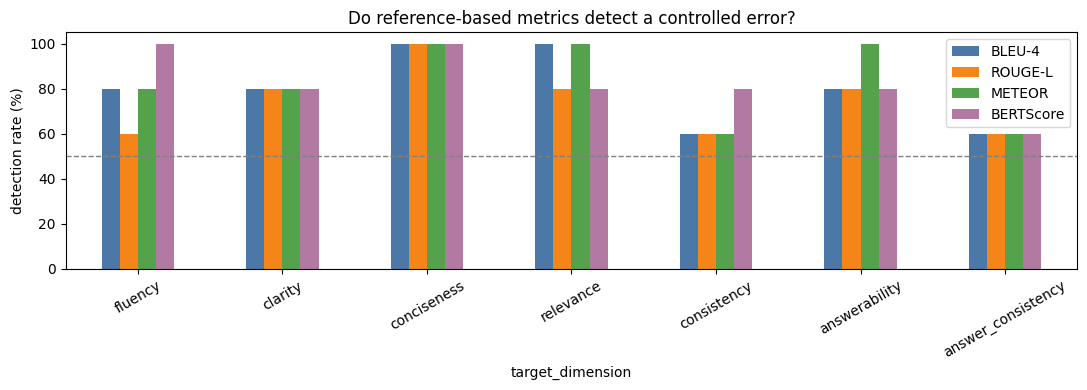

In [ ]:
import nltk, numpy as np, matplotlib.pyplot as plt
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer
from bert_score import score as bert_score
nltk.download("wordnet", quiet=True); nltk.download("omw-1.4", quiet=True)

METRICS = ["BLEU-4", "ROUGE-L", "METEOR", "BERTScore"]
smooth = SmoothingFunction().method1
rs = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)
def scores(hyps, refs):
    out = {"BLEU-4": [sentence_bleu([r.split(" ")], h.split(" "), smoothing_function=smooth) for h, r in zip(hyps, refs)],
           "ROUGE-L": [rs.score(h, r)["rougeL"].fmeasure for h, r in zip(hyps, refs)],
           "METEOR": [meteor_score([r.split(" ")], h.split(" ")) for h, r in zip(hyps, refs)],
           "BERTScore": bert_score(hyps, refs, lang="en", verbose=False)[2].tolist()}
    return pd.DataFrame(out)

refs = done.reference_question.tolist()       # QGEval human reference question
valid = scores(done.valid_question.tolist(), refs)
pert = scores(done.perturbed_question.tolist(), refs)
for m in METRICS:
    done[f"{m}_valid"] = valid[m].values
    done[f"{m}_perturbed"] = pert[m].values
    done[f"{m}_detected"] = done[f"{m}_perturbed"] < done[f"{m}_valid"]

detect = pd.DataFrame({m: done.groupby("target_dimension")[f"{m}_detected"].mean().reindex(DIMS) * 100
                       for m in METRICS}).round(0)
detect.loc["ALL"] = [round(done[f"{m}_detected"].mean() * 100) for m in METRICS]
print("Detection rate (%): how often the metric scores the perturbed question LOWER than the valid one\n")
print(detect.to_string())

ax = detect.drop("ALL").plot.bar(figsize=(11, 4), color=["#4C78A8", "#F58518", "#54A24B", "#B279A2"])
ax.axhline(50, color="grey", ls="--", lw=1)
ax.set(title="Do reference-based metrics detect a controlled error?", ylabel="detection rate (%)", ylim=(0, 105))
ax.tick_params(axis="x", rotation=30); plt.tight_layout()
plt.savefig("controlled_detection.png", dpi=200); plt.show()

## Step 6 — Save results and dataset card

In [ ]:
done.to_csv("controlled_dataset_v1.csv", index=False)
detect.to_csv("controlled_detection_rates.csv")
card = f"""# Controlled Question Quality Dataset (pilot v1)
**Purpose:** test whether QG evaluation metrics notice a known, deliberately introduced error in each of QGEval's 7 dimensions.
**Collection:** {len(src)} base items ({N_SQUAD} SQuAD, {N_HOTPOT} HotpotQA) from QGEval, each with a model-generated question rated 3/3 on all 7 dimensions by all 3 QGEval annotators (human-verified valid), passage <= {MAX_PASSAGE_WORDS} words, seed {SEED}.
**Construction:** for every base item, one perturbed question per target dimension, following a fixed rule per dimension; drafted with a large language model (LLM) (35 usable items of 35; 0 edited by the author).
**Annotation:** each item labelled with target dimension and perturbation type; the LLM self-checked whether only the target dimension is broken, and the author reviewed every check (author: yes 19, partly 16, no 0; author changed the LLM's check on 2 of 35 items).
**Evaluation:** BLEU-4, ROUGE-L, METEOR and BERTScore computed for valid and perturbed questions against the QGEval reference; detection = perturbed scored lower than valid.
**Known limitation:** errors are not perfectly isolated (e.g. fluency errors also lower clarity), so labels mark the PRIMARY intended error; pilot size is small.
"""
open("controlled_dataset_card.md", "w").write(card)
print(card)
for f in ["controlled_dataset_v1.csv", "controlled_detection_rates.csv", "controlled_detection.png",
          "controlled_dataset_card.md"]:
    files.download(f)

# Controlled Question Quality Dataset (pilot v1)
**Purpose:** test whether QG evaluation metrics notice a known, deliberately introduced error in each of QGEval's 7 dimensions.
**Collection:** 5 base items (3 SQuAD, 2 HotpotQA) from QGEval, each with a model-generated question rated 3/3 on all 7 dimensions by all 3 QGEval annotators (human-verified valid), passage <= 120 words, seed 42.
**Construction:** for every base item, one perturbed question per target dimension, following a fixed rule per dimension; drafted with a large language model (LLM) (35 usable items of 35; 0 edited by the author).
**Annotation:** each item labelled with target dimension and perturbation type; the LLM self-checked whether only the target dimension is broken, and the author reviewed every check (author: yes 19, partly 16, no 0; author changed the LLM's check on 2 of 35 items).
**Evaluation:** BLEU-4, ROUGE-L, METEOR and BERTScore computed for valid and perturbed questions against the QGEval reference; dete

In [2]:
# Step 7 - Blind re-check of the controlled dataset labels
# Upload: controlled_dataset_build.xlsx
import os, re
import pandas as pd
try:
    from google.colab import files
    print("Upload: controlled_dataset_build.xlsx")
    for name in files.upload():
        clean = re.sub(r" \(\d+\)", "", name)
        if clean != name:
            os.replace(name, clean)
except ImportError:
    pass

DIMS = ["fluency", "clarity", "conciseness", "relevance",
        "consistency", "answerability", "answer_consistency"]
blind = pd.read_excel("controlled_dataset_build.xlsx", sheet_name="blind_check")
build = pd.read_excel("controlled_dataset_build.xlsx", sheet_name="build")
norm = lambda s: s.astype(str).str.strip().str.lower()
blind["main_problem"] = norm(blind.main_problem.fillna(""))
blind["also_affects"] = norm(blind.also_affects.fillna("none")).replace("", "none")
build["key"] = norm(build.perturbed_question)
blind["key"] = norm(blind.perturbed_question)
m = blind.merge(build[["key", "item_id", "target_dimension"] +
                      (["llm_self_check"] if "llm_self_check" in build else [])], on="key", how="left")

done = m[m.main_problem.isin(DIMS)].copy()
print(f"Items checked blind: {len(done)} / {len(m)}   (unmatched to dataset: {int(m.item_id.isna().sum())})")
assert len(done) > 0, "Fill main_problem first"

done["correct"] = done.main_problem == done.target_dimension
done["second_dim_seen"] = done.also_affects != "none"
print(f"\nIntended error identified (blind): {done.correct.sum()} / {len(done)} = {done.correct.mean()*100:.0f}%")

per = done.groupby("target_dimension").agg(items=("correct", "size"),
                                           identified=("correct", "sum")).reindex(DIMS)
per["identified %"] = (per.identified / per["items"] * 100).round(0)
print("\nPer intended dimension:\n")
print(per.to_string())

confusion = pd.crosstab(done.target_dimension, done.main_problem).reindex(index=DIMS, columns=DIMS, fill_value=0)
print("\nConfusion (rows = intended error, columns = what I identified):\n")
print(confusion.to_string())

if "llm_self_check" in done:
    llm_partly = norm(done.llm_self_check) == "partly"
    agree = (llm_partly == done.second_dim_seen).mean() * 100
    print(f"\nSecond dimension also affected: me {int(done.second_dim_seen.sum())} items, "
          f"LLM self-check 'partly' {int(llm_partly.sum())} items, agreement {agree:.0f}%")

wrong = done[~done.correct][["item_id", "target_dimension", "main_problem", "perturbed_question"]]
if len(wrong):
    print("\nItems where my reading differed from the intended label:\n")
    print(wrong.to_string(index=False))

with pd.ExcelWriter("controlled_blind_results.xlsx") as xw:
    per.to_excel(xw, sheet_name="per_dimension")
    confusion.to_excel(xw, sheet_name="confusion")
    done.drop(columns=["key"]).to_excel(xw, sheet_name="items", index=False)
print("\nSaved: controlled_blind_results.xlsx")
try:
    files.download("controlled_blind_results.xlsx")
except Exception:
    pass

Upload: controlled_dataset_build.xlsx


Saving controlled_dataset_build.xlsx to controlled_dataset_build (1).xlsx
Items checked blind: 35 / 35   (unmatched to dataset: 0)

Intended error identified (blind): 33 / 35 = 94%

Per intended dimension:

                    items  identified  identified %
target_dimension                                   
fluency                 5           5         100.0
clarity                 5           5         100.0
conciseness             5           5         100.0
relevance               5           4          80.0
consistency             5           5         100.0
answerability           5           5         100.0
answer_consistency      5           4          80.0

Confusion (rows = intended error, columns = what I identified):

main_problem        fluency  clarity  conciseness  relevance  consistency  answerability  answer_consistency
target_dimension                                                                                            
fluency                   5        0     